# Notebook 6: Held-out benchmark (following the IDS 560 Benchmark Guide)
**IDS 560, Group 4, M5 inventory agent (v4).** Notebooks 1–5 are unchanged. This notebook only **adds** an evaluation that follows the course's Benchmark Guide:

| Guide step | What this notebook does |
|---|---|
| 1. Decision to support | Can the agent turn a forecast into a sound order and answer a store manager's questions, with evidence, better than simpler systems? |
| 2. Test cases | A **case file** with one record per case: category, input, data snapshot, expected outcome, evidence, scoring rule, split, provenance and reviewer. |
| 3. Development vs. test | The 56 questions and 10 scenarios from notebooks 2–3 were used to tune the system, so they are the **development set**. The **held-out test set** is new: later dates (2016), new wording, picked before seeing any result. |
| 4. Comparisons | Four systems on the same cases, model and data: **Direct LLM** (no retrieval, no tools), **Basic RAG** (meaning-only search, as in v1–v2, no forecast lookup, flags or reranker), **our agent** (`recommend()` / `ask()`, as in notebook 3) and **our agent with checks** (`recommend_checked()` / `answer_checked()`, the version the dashboard uses: validation checks with one retry, item questions, missing dates and stores). |
| 5. Metrics | Task success (numerator / denominator), grounding (valid citations, numbers found in the sources), time, model calls, tokens and cost per case. |
| 6. Validate the scoring | A **hand-review sheet**: a person scores a sample of answers and the notebook reports how often the automatic score agrees. Each case runs **twice** to show run-to-run variation. |
| 7. Report honestly | Results with counts, failed runs, failure types and one example of each, plus a run-info file (model, prompts, data versions). |

**Model calls:** about 36 test cases × 4 systems × 2 runs ≈ 290, plus a few retries by the checked agent. The free OpenRouter tier allows about 50 a day, so use the $10 credit (1,000 a day) or run it over several days: **finished runs are saved after every case and skipped when you rerun**, so an interrupted run just continues.

Everything is saved to `RAG FILES/` with names starting `heldout_`.

## 1. Setup

In [1]:
!pip -q install sentence-transformers openai pypdf
import sys, importlib, hashlib
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
RAG_FILES = "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/"   # rag_common.py lives here
sys.path.insert(0, RAG_FILES)
import rag_common as rc
importlib.reload(rc)
rc.setup(m5=True, forecasts=True, library=True)
from rag_common import *
import matplotlib.pyplot as plt

# Settings
N_RUNS = 2                                    # each case is run this many times per system (run-to-run variation)
SYSTEMS = ["direct_llm", "basic_rag", "agent", "agent_checked"]   # drop "agent_checked" to compare only the first three
PAUSE = 4                                     # seconds between model calls (free-tier limits)
SEED = 560                                    # picks the held-out order cases; fixed so every run uses the same cases
REVIEWER = ""                                 # name of the team member who reviewed the case file (step 2), e.g. "Tyler"
print("Model:", rc.OPENROUTER_MODEL)

Mounted at /content/drive
M5 data: 30,490 series x 1,941 days | prices for 79% of series-weeks
Forecast cube: 15,245 series, 72 weekly forecasts (2014-12-31 to 2016-05-12), 14 days each
Segments: 15,245 series | model error by segment: 2,130 rows
Past launches: 16,610 | new-item method: cascade + own sales


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

... (15 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Library: 7,537 passages from 5,000 documents | reranker on | RELEVANCE_MIN 0.015
Setup done in 81s | files are read from and saved to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/ (names end in _v4)
Model: anthropic/claude-haiku-5.5


## 2. The case file
**Development set** (`split = development`): the 56 retrieval/agent questions and the 10 scenario orders from notebooks 2–3. They were used to choose the relevance cut-off and to adjust the prompt, so they are not used for the final results.

**Held-out test set** (`split = test`), all on 2016 dates (the forecasting model's test period), none seen during tuning:

| Category | Cases | Expected outcome | Success rule (fixed before running) |
|---|---|---|---|
| `order` | 12 | Covers actual 14-day demand without large overstock | Stock on hand + order ≥ actual demand, and leftover ≤ actual demand + 3 units. A held order is scored on its "if confirmed" quantity. |
| `forecast_data` | 10 | Names the right result (top item, store, category, peak day…) | The answer contains the result computed from the forecast cube for the intended question type |
| `evidence` | 6 | A supported answer | Does not claim "no evidence" and cites at least one passage that matches the case's expected document type and terms |
| `no_answer` | 6 | Says the data does not contain it | The answer says the evidence is missing |
| `unusual` | 2 | Handles a store or date with no data | Says that store or date has no data, instead of inventing a number or failing |

Order cases are picked at random (seed 560) from the forecasting model's 50% sample: 3 items per category with recent sales, plus a recent zero-sales run, a new item and a stopped item. The questions were drafted for this test set and **must be reviewed by a team member** (guide step 2) before the final run: check the wording, the expected type and terms, and set `REVIEWER` above. The check below confirms that evidence matching each `evidence` case exists in the library on its date.

In [2]:
IN_SAMPLE = ids["id"].isin(SAMPLE_IDS).to_numpy() if SAMPLE_IDS else np.ones(len(ids), bool)
LIBRARY_VERSION = f"chunks_{rc.RUN_TAG}.pkl: {len(rc.chunks):,} passages, id hash {hashlib.md5(''.join(rc.chunks['chunk_id']).encode()).hexdigest()[:8]}"
CUBE_VERSION = (f"forecast_cube_lightgbm_50.npz: {len(rc.CUBE['origins'])} weekly forecasts "
                f"{rc.CUBE['origins'][0]:%Y-%m-%d} to {rc.CUBE['origins'][-1]:%Y-%m-%d}") if rc.CUBE else "no forecast cube"

def snap_to_forecast(date):
    """The latest weekly forecast date on or before `date` (questions about 'next week' use that forecast)."""
    if rc.CUBE is None:
        return date
    o = rc.CUBE["origins"][rc.CUBE["origins"] <= pd.Timestamp(date)]
    return f"{o[-1]:%Y-%m-%d}" if len(o) else date

# ---- Development set: what notebooks 2-3 used
def provenance_of(tid):
    return ("v1-v2 tests" if tid <= 16 else "team question list 1" if tid <= 26 else "team question list 2" if tid <= 36
            else "team question list 3")
CASES = []
for tid, q, as_of, st, types, terms, kind, lookup in rc.TESTS:
    CASES.append({"case_id": f"dev-q{tid}", "split": "development", "category": {"data": "forecast_data", "no_evidence": "no_answer"}.get(kind, "evidence"),
                  "input": q, "as_of": as_of, "state": st, "expected_types": types, "expected_terms": terms, "intended_lookup": lookup,
                  "expected_outcome": "", "provenance": provenance_of(tid) + " (used for tuning in notebooks 2-3)", "reviewer": "team"})

# ---- Held-out test set: questions (drafted for this notebook; to be reviewed)
TEST_QUESTIONS = [
    # (id, category, question, date, state, expected types, expected terms, intended lookup)
    ("t-q01", "forecast_data", "What item is forecast to have the highest demand next week across our stores?", "2016-01-20", None, None, [], "top_items"),
    ("t-q02", "forecast_data", "Next week, which category will see the most demand overall?", "2016-02-03", None, None, [], "by_category"),
    ("t-q03", "forecast_data", "Which store should expect the most customer demand in the next 7 days?", "2016-02-17", None, None, [], "by_store"),
    ("t-q04", "forecast_data", "Which day next week will demand peak, and how does it change day to day?", "2016-03-02", None, None, [], "daily_profile"),
    ("t-q05", "forecast_data", "Which items are most at risk of a stockout this coming week?", "2016-03-16", None, None, [], "stockout_risk"),
    ("t-q06", "forecast_data", "If supply is tight, which stores should we send inventory to first?", "2016-03-30", None, None, [], "replenish_stores"),
    ("t-q07", "forecast_data", "Do we have excess stock on any items given next week's forecast?", "2016-04-13", None, None, [], "excess_items"),
    ("t-q08", "forecast_data", "Compare expected shortages at TX_1 and WI_2 for next week.", "2016-04-27", None, None, [], "compare_stores"),
    ("t-q09", "forecast_data", "Which products should get restocked first based on predicted shortages?", "2016-01-27", None, None, [], "replenish_items"),
    ("t-q10", "forecast_data", "Which departments look most likely to run short next week?", "2016-02-24", None, None, [], "dept_shortage"),
    ("t-q11", "evidence", "Should a Wisconsin store expect winter weather to hurt Hobbies sales this month?", "2016-01-13", "WI", ["evidence_card", "storm_event"], ["snow", "winter"], None),
    ("t-q12", "evidence", "How do SNAP benefit days change Foods sales in Texas?", "2016-02-10", "TX", ["evidence_card", "reference", "policy_doc"], ["snap"], None),
    ("t-q13", "evidence", "What were Walmart's latest comments on U.S. comparable sales?", "2016-03-15", None, ["sec_filing", "walmart_doc"], ["comparable"], None),
    ("t-q14", "evidence", "What is the San Francisco Fed hearing from retailers about consumer spending?", "2016-03-10", "CA", ["beige_book"], ["san francisco"], None),
    ("t-q15", "evidence", "Which months are busiest for Household sales in California?", "2016-01-27", "CA", ["evidence_card"], ["month", "seasonal"], None),
    ("t-q16", "evidence", "How much do holidays like Easter change store sales?", "2016-03-16", None, ["evidence_card"], ["easter", "event"], None),
    ("t-q17", "no_answer", "What was the gross margin on Foods items at CA_1 last quarter?", "2016-02-03", "CA", None, [], None),
    ("t-q18", "no_answer", "How many units did WI_3 receive from the distribution center last week?", "2016-03-02", "WI", None, [], None),
    ("t-q19", "no_answer", "Which items had the most price-match requests from customers this month?", "2016-03-30", None, None, [], None),
    ("t-q20", "no_answer", "What is the shelf capacity for paper towels at TX_2?", "2016-04-13", "TX", None, [], None),
    ("t-q21", "no_answer", "How did online pickup orders change at Texas stores this year?", "2016-04-20", "TX", None, [], None),
    ("t-q22", "no_answer", "How many labor hours did each store schedule for Black Friday 2015?", "2016-01-06", None, None, [], None),
    ("t-q23", "unusual", "Compare expected shortages at CA_9 and TX_1 for next week.", "2016-02-17", None, None, ["ca_9"], "compare_stores"),
    ("t-q24", "unusual", "Which store has the highest predicted demand over the next 7 days?", "2014-06-04", None, None, ["forecast"], "by_store"),
]
OUTCOME = {"forecast_data": "Names the result the forecast cube gives for the intended question type",
           "evidence": "Supported answer: cites a passage of the expected type with the expected terms; does not claim there is no evidence",
           "no_answer": "Says the data does not contain this (no made-up answer)",
           "unusual": "Says this store or date has no data, without inventing numbers or failing"}
for cid, cat, q, d, st, types, terms, lookup in TEST_QUESTIONS:
    as_of = snap_to_forecast(d) if cat in ("forecast_data",) else d
    CASES.append({"case_id": cid, "split": "test", "category": cat, "input": q, "as_of": as_of, "state": st, "expected_types": types,
                  "expected_terms": terms, "intended_lookup": lookup, "expected_outcome": OUTCOME[cat],
                  "provenance": "drafted for the held-out set (synthetic wording); 2016 dates", "reviewer": REVIEWER})

# ---- Development scenario orders (notebook 3) and held-out test orders
for i, (cat, store, d, kind) in enumerate([("HOBBIES", "WI_2", "2015-01-07", "top"), ("FOODS", "TX_1", "2015-08-05", "top"),
        ("FOODS", "TX_3", "2015-05-27", "top"), ("FOODS", "CA_1", "2015-11-18", "top"), ("FOODS", "CA_1", "2015-12-16", "top"),
        ("HOUSEHOLD", "TX_2", "2015-06-03", "intermittent"), (None, "WI_1", "2015-09-02", "zero_run"), ("HOUSEHOLD", "CA_2", "2016-05-05", "top"),
        (None, None, "2015-07-01", "new_item"), (None, None, "2015-09-30", "stopped")], 1):
    CASES.append({"case_id": f"dev-o{i}", "split": "development", "category": "order", "input": f"scenario order: {kind} {cat or ''} {store or ''}".strip(),
                  "as_of": d, "state": store[:2] if store else None, "expected_outcome": "", "provenance": "notebook 3 scenarios (used for tuning)",
                  "reviewer": "team"})

def actual_sales(row, as_of, days):
    end = int(day_index[pd.Timestamp(as_of)])
    return float(vals[row, end + 1: end + 1 + days].sum())

def zero_run_item(as_of, rng):
    end = int(day_index[pd.Timestamp(as_of)])
    recent, before = vals[:, end - 20: end + 1], vals[:, end - 200: end - 20]
    pool = np.flatnonzero(IN_SAMPLE & (recent.sum(1) == 0) & ((before > 0).sum(1) > 60))
    return rng.choice(pool) if len(pool) else None

def new_item_row(as_of, rng, min_days=14, max_days=42):
    end = int(day_index[pd.Timestamp(as_of)])
    pos = vals[:, : end + 1] > 0
    first = np.where(pos.any(1), pos.argmax(1), -1)
    pool = np.flatnonzero(IN_SAMPLE & (first >= end - max_days + 1) & (first <= end - min_days + 1))
    return rng.choice(pool) if len(pool) else None

def stopped_row(as_of, rng, min_run=60):
    end = int(day_index[pd.Timestamp(as_of)])
    recent = vals[:, end - min_run + 1: end + 1].sum(1)
    before = (vals[:, max(0, end - min_run - 364): end - min_run + 1] > 0).sum(1)
    pool = np.flatnonzero(IN_SAMPLE & (recent == 0) & (before >= 60))
    return rng.choice(pool) if len(pool) else None

def build_test_orders(seed=SEED):
    """12 held-out orders on 2016 weekly forecast dates whose next 28 days of sales are known."""
    rng = np.random.default_rng(seed)
    last = cal["date"].iloc[vals.shape[1] - 1] - pd.Timedelta(days=28)
    dates = [d for d in (rc.CUBE["origins"] if rc.CUBE else pd.date_range("2016-01-06", last, freq="7D"))
             if pd.Timestamp("2016-01-01") <= d <= last]
    picks = []
    for cat in CATS:
        for _ in range(3):
            d = rng.choice(dates)
            end = int(day_index[pd.Timestamp(d)])
            pool = np.flatnonzero(IN_SAMPLE & (ids["cat_id"] == cat).to_numpy() & ((vals[:, end - 27: end + 1] > 0).sum(1) >= 4))
            picks.append(("regular", d, rng.choice(pool) if len(pool) else None))
    for kind, fn in [("zero_run", zero_run_item), ("new_item", new_item_row), ("stopped", stopped_row)]:
        for _ in range(5):                                  # try a few dates until one has a suitable item
            d = rng.choice(dates)
            r = fn(d, rng)
            if r is not None:
                break
        picks.append((kind, d, r))
    out = []
    for n, (kind, d, r) in enumerate(picks, 1):
        if r is None:
            print("No suitable item for", kind); continue
        item, store = ids["item_id"].iloc[r], ids["store_id"].iloc[r]
        d = f"{pd.Timestamp(d):%Y-%m-%d}"
        fc = baseline_forecast(item, store, d, quiet=True)
        on_hand = int(round(float(np.sum(fc["mean"][:7]))))
        end = int(day_index[pd.Timestamp(d)])
        out.append({"case_id": f"t-o{n:02d}", "split": "test", "category": "order", "input": f"order for {item} at {store}",
                    "item_id": item, "store_id": store, "as_of": d, "state": store[:2], "order_kind": kind, "on_hand": on_hand,
                    "recent_avg_daily": round(float(vals[r, end - 27: end + 1].mean()), 2), "last_7_days": int(vals[r, end - 6: end + 1].sum()),
                    "actual_14_days": actual_sales(r, d, 14), "actual_28_days": actual_sales(r, d, 28),
                    "expected_outcome": "Stock on hand + order covers actual 14-day demand, leftover at most actual demand + 3 units",
                    "provenance": f"random pick (seed {seed}) from the forecasting model's 50% sample, 2016 test period", "reviewer": REVIEWER})
    return out

CASES += build_test_orders()
for c in CASES:
    c["data_snapshot"] = f"{LIBRARY_VERSION}; {CUBE_VERSION}; M5 sales up to {c['as_of']}"
    c.setdefault("scoring", {"order": "covers 14-day demand, leftover <= demand + 3", "forecast_data": "names the lookup result",
                             "evidence": "cites a matching passage, no false 'no evidence'", "no_answer": "says evidence is missing",
                             "unusual": "says the store/date has no data"}[c["category"]])
cases = pd.DataFrame(CASES)
TEST = cases[cases["split"] == "test"].reset_index(drop=True)
print(cases.groupby(["split", "category"]).size().unstack(fill_value=0))

# Check the evidence cases: does a matching passage exist in the library on that date? (guide step 6.1)
def matches(r, types, terms):
    txt = (str(r["title"]) + " " + str(r["text"])).lower()
    return (not types or r["doc_type"] in types) and (not terms or any(t in txt for t in terms))
chk = []
for _, c in TEST[TEST["category"] == "evidence"].iterrows():
    el = rc.eligible_passages(c["as_of"], c["state"])
    n = int(sum(matches(r, c["expected_types"], c["expected_terms"]) for _, r in el.iterrows()))
    chk.append({"case_id": c["case_id"], "question": c["input"][:70], "matching_passages": n, "ok": n > 0})
for _, c in TEST[TEST["category"].isin(["forecast_data"])].iterrows():
    chk.append({"case_id": c["case_id"], "question": c["input"][:70], "matching_passages": None, "ok": rc.cube_slot(c["as_of"]) is not None})
chk = pd.DataFrame(chk)
display(chk)
if (~chk["ok"]).any():
    print("Fix these cases before the final run (no evidence or no forecast on that date):", chk.loc[~chk["ok"], "case_id"].tolist())
if not REVIEWER:
    print("REVIEWER is empty: have a team member review the case file (heldout_cases_v4.csv) and set REVIEWER before the final run.")
cases.to_json(out_path("heldout_cases.json"), orient="records", indent=1, date_format="iso")
cases.to_csv(out_path("heldout_cases.csv"), index=False)
display(TEST[TEST["category"] == "order"][["case_id", "item_id", "store_id", "as_of", "order_kind", "on_hand", "recent_avg_daily", "actual_14_days"]])

category     evidence  forecast_data  no_answer  order  unusual
split                                                          
development        34             12         10     10        0
test                6             10          6     12        2


,case_id,question,matching_passages,ok
0,t-q11,Should a Wisconsin store expect winter weather...,10.0,True
1,t-q12,How do SNAP benefit days change Foods sales in...,8.0,True
2,t-q13,What were Walmart's latest comments on U.S. co...,33.0,True
3,t-q14,What is the San Francisco Fed hearing from ret...,57.0,True
4,t-q15,Which months are busiest for Household sales i...,11.0,True
5,t-q16,How much do holidays like Easter change store ...,39.0,True
6,t-q01,What item is forecast to have the highest dema...,NaN,True
7,t-q02,"Next week, which category will see the most de...",NaN,True
8,t-q03,Which store should expect the most customer de...,NaN,True
9,t-q04,"Which day next week will demand peak, and how ...",NaN,True


REVIEWER is empty: have a team member review the case file (heldout_cases_v4.csv) and set REVIEWER before the final run.


,case_id,item_id,store_id,as_of,order_kind,on_hand,recent_avg_daily,actual_14_days
24,t-o01,FOODS_3_509,TX_1,2016-04-07,regular,3.0,0.29,6.0
25,t-o02,FOODS_1_144,CA_1,2016-03-10,regular,5.0,0.82,16.0
26,t-o03,FOODS_2_115,TX_2,2016-02-11,regular,16.0,2.25,32.0
27,t-o04,HOBBIES_1_234,CA_2,2016-02-18,regular,25.0,3.43,46.0
28,t-o05,HOBBIES_1_383,CA_2,2016-01-07,regular,6.0,0.93,4.0
29,t-o06,HOBBIES_1_252,TX_2,2016-02-11,regular,16.0,2.46,20.0
30,t-o07,HOUSEHOLD_1_238,TX_2,2016-01-28,regular,6.0,0.64,9.0
31,t-o08,HOUSEHOLD_2_346,TX_2,2016-02-11,regular,8.0,1.25,23.0
32,t-o09,HOUSEHOLD_1_404,WI_3,2016-01-28,regular,10.0,1.36,26.0
33,t-o10,FOODS_3_722,WI_3,2016-01-28,zero_run,0.0,0.00,0.0


## 3. The four systems
All four use the same model (`rc.OPENROUTER_MODEL`), the same cases and the same answer format, so the scoring is identical.

| System | Questions | Orders |
|---|---|---|
| **Direct LLM** | The question and decision date only; no documents, no tools | Item, store, date, stock on hand, lead time and the item's recent sales (28-day average, last 7 days), the facts a manager would type in |
| **Basic RAG** | Top 8 passages by meaning only (the v1–v2 search: no category filter, keyword search or reranker), no forecast lookup | Same facts as Direct LLM plus the top 6 passages for the item's category and state |
| **Our agent** | `ask()`: filters, hybrid search, reranker, forecast-data lookup | `recommend()`: forecast, ordering rule, flags, hold rule, confidence, item profile, evidence |
| **Our agent with checks** | `answer_checked()`: `ask()` plus item questions, a note for dates without a forecast and unknown stores, the validation checks and one retry | `recommend_checked()`: `recommend()` plus the validation checks and one retry |

The checked agent's handling of dates without a forecast and of unknown stores was added after the first (partial) run of this notebook showed the plain agent failing case t-q24. Report it that way: the plain agent's result on t-q23/t-q24 is the untuned one.

Every model call is logged with its time, tokens and cost (OpenRouter reports cost when usage accounting is on).

In [12]:
CALL_LOG = []
OR_KEY = rc.get_secret("OPENROUTER_API_KEY")      # read once: Colab's Secrets lookup can time out if repeated for every call
print("OpenRouter key:", "found" if OR_KEY else "NOT FOUND - add OPENROUTER_API_KEY in Colab Secrets and turn on notebook access")

def logged_generate_text(system, prompt, max_tokens=1200):
    """rc.generate_text with time, tokens and cost logged. Used by all three systems (the agent's functions call it too).
    A missing key is an error (so the run is retried), not a silent empty answer."""
    global OR_KEY
    key = OR_KEY or rc.get_secret("OPENROUTER_API_KEY")
    if not key:
        raise RuntimeError("No OPENROUTER_API_KEY could be read from Colab Secrets")
    OR_KEY = key
    from openai import OpenAI
    client = OpenAI(base_url=rc.OPENROUTER_URL, api_key=key, timeout=rc.LLM_TIMEOUT, max_retries=3)
    text = ""
    for attempt in range(2):
        t = time.time()
        resp = client.chat.completions.create(model=rc.OPENROUTER_MODEL, max_tokens=max(max_tokens, 6000), extra_body={"usage": {"include": True}},
                                              messages=[{"role": "system", "content": system}, {"role": "user", "content": prompt}])
        u = getattr(resp, "usage", None)
        extra = (getattr(u, "model_extra", None) or {}) if u is not None else {}
        CALL_LOG.append({"seconds": time.time() - t, "prompt_tokens": getattr(u, "prompt_tokens", None),
                         "completion_tokens": getattr(u, "completion_tokens", None), "cost_usd": getattr(u, "cost", None) or extra.get("cost")})
        text = resp.choices[0].message.content or ""
        if text.strip():
            return text
        if attempt == 0:
            time.sleep(10)
    return text
rc.generate_text = logged_generate_text          # in this notebook only: recommend() and ask() now log their calls too

DIRECT_PROMPT = """You answer questions from a Walmart store manager. You have no documents or data tools.
Rules:
- If you cannot answer from what you know, start the answer with "No supporting evidence found" and say what data would be needed.
- Be brief and concrete. Format:
Answer: <two to four sentences>
Why:
- <reason>
What the data cannot tell us:
- <limit, or "nothing important">
Evidence used: none"""

ORDER_PROMPT = """You are an inventory decision-support assistant for a Walmart store manager.
Recommend how many units to order now. The order arrives after the lead time and must cover demand until the next order.
If evidence passages [E1], [E2], ... are given, cite them for each reason; otherwise reason from the numbers given.
Format:
Recommendation: order <N> units.
Why:
- <reason>
Manager checks:
- <what to double-check>
Evidence used: <list of E numbers, or none>"""

def order_facts(c):
    return (f"Item {c['item_id']} (category {c['item_id'].split('_')[0]}) at store {c['store_id']} in {STATE_NAMES[c['state']]}. "
            f"Decision date: {c['as_of']}. Stock on hand: {c['on_hand']} units. Lead time 7 days, review period 7 days, so the order must "
            f"cover the next 14 days. Average daily sales over the last 28 days: {c['recent_avg_daily']} units; units sold in the last 7 days: "
            f"{c['last_7_days']}.")

def passages_text(ev):
    return "\n".join(f"[E{n}] ({r['doc_type']}, {r['source']}, published {r['published']:%Y-%m-%d}, {r['state']}) {r['title']}\n{r['text'][:1500]}"
                     for n, (_, r) in enumerate(ev.iterrows(), 1)) or "(no passages found)"

def run_system(system, c):
    """One case on one system. Returns the answer, the prompt it saw, its evidence and (orders) its quantity."""
    out = {"answer": None, "prompt": None, "evidence": None, "order_qty": None, "hold": False, "if_confirmed_qty": None, "routed_to": None}
    if c["category"] == "order":
        if system == "agent_checked":
            fc = baseline_forecast(c["item_id"], c["store_id"], c["as_of"], quiet=True)
            res = rc.recommend_checked(c["item_id"], c["store_id"], c["as_of"], on_hand=c["on_hand"], forecast=fc)
            q = res["order"]
            out.update(answer=res["answer"], prompt=res["prompt"], evidence=res["evidence"], order_qty=q["order_qty"], hold=bool(q["hold"]),
                       if_confirmed_qty=q.get("if_confirmed_order_qty"), attempts=res["attempts"], checks_failed=", ".join(res["failed"]))
            return out
        if system == "agent":
            fc = baseline_forecast(c["item_id"], c["store_id"], c["as_of"], quiet=True)
            res = recommend(c["item_id"], c["store_id"], c["as_of"], on_hand=c["on_hand"], forecast=fc, verbose=False)
            q = res["order"]
            out.update(answer=res["answer"], prompt=res["prompt"], evidence=res["evidence"], order_qty=q["order_qty"], hold=bool(q["hold"]),
                       if_confirmed_qty=q.get("if_confirmed_order_qty"), flags=", ".join(f["code"] for f in res["flags"]),
                       confidence=res["confidence"]["level"], rule_res=res)
            return out
        ev = None
        prompt = order_facts(c)
        if system == "basic_rag":
            cat = c["item_id"].split("_")[0].lower()
            ev = retrieve(f"{cat} demand and sales outlook in {STATE_NAMES[c['state']]}", c["as_of"], c["state"], k=6, method="dense").reset_index(drop=True)
            prompt += "\n\nEvidence:\n" + passages_text(ev)
        ans = logged_generate_text(ORDER_PROMPT, prompt)
        out.update(answer=ans, prompt=prompt, evidence=ev, order_qty=parse_qty(ans))
        return out
    q, as_of, st = c["input"], c["as_of"], c["state"]
    if system == "agent_checked":
        res = rc.answer_checked(q, as_of, st)
        out.update(answer=res["answer"], prompt=res["prompt"], evidence=res["evidence"], routed_to=res["lookup"]["kind"] if res["lookup"] else None,
                   attempts=res["attempts"], checks_failed=", ".join(res["failed"]))
        return out
    if system == "agent":
        res = ask(q, as_of, st, verbose=False)
        out.update(answer=res["answer"], prompt=res["prompt"], evidence=res["evidence"], routed_to=res["lookup"]["kind"] if res["lookup"] else None)
        return out
    if system == "basic_rag":
        ev = retrieve(q, as_of, st, k=8, method="dense").reset_index(drop=True)
        prompt = (f"Decision date: {pd.Timestamp(as_of):%Y-%m-%d}. Store state: {STATE_NAMES.get(st, 'any')}. Question: {q}\n\nEvidence:\n" + passages_text(ev))
        out.update(answer=logged_generate_text(rc.ASK_PROMPT, prompt), prompt=prompt, evidence=ev)
        return out
    prompt = f"Decision date: {pd.Timestamp(as_of):%Y-%m-%d}. Store state: {STATE_NAMES.get(st, 'any')}. Question: {q}"
    out.update(answer=logged_generate_text(DIRECT_PROMPT, prompt), prompt=prompt)
    return out

def parse_qty(answer):
    """The quantity on the Recommendation line (the last number there, so 'if confirmed, order N' is read as N)."""
    if not answer:
        return None
    m = re.search(r"Recommendation:(.*)", answer)
    nums = re.findall(r"\d[\d,]*(?:\.\d+)?", (m.group(1) if m else answer).replace(",", ""))
    return int(round(float(nums[-1]))) if nums else None

OpenRouter key: found


## 4. Scoring rules (fixed before the run)
**Task success** follows the table in section 2. **Grounding** is scored the same way for every system: every [E#] points to a passage it was given (`citations_valid`), and every number in the answer appears in what the system was given (`numbers_verified`, the same check as notebook 3). A Direct LLM answer cannot cite anything, so its "evidence" cases can't succeed: the guide's definition of success includes being supported.

The order outcome uses actual M5 sales after the decision date, which no system sees.

In [4]:
NUM_RE = re.compile(r"(?<![\w.])[-−+]?\d[\d,]*(?:\.\d+)?")
MISSING_WORDS = ("no supporting evidence", "does not contain", "doesn't contain", "not in the data", "cannot be answered", "not available",
                 "no data", "not included", "isn't in the data", "is not in the data", "no information")
UNUSUAL_WORDS = ("not found", "no forecast", "does not exist", "doesn't exist", "not a valid", "no such store", "not covered", "outside")
def _numbers(text):
    text = re.sub(r"\[?E\d+\]?", " ", text); text = re.sub(r"\d{4}-\d{2}-\d{2}", " ", text)
    out = []
    for m in NUM_RE.findall(text):
        s = m.replace(",", "").replace("−", "-").lstrip("+")
        try:
            out.append((float(s), len(s.split(".")[1]) if "." in s else 0))
        except ValueError:
            pass
    return out

def unverified_numbers(answer, prompt):
    have = [abs(v) for v, _ in _numbers(prompt)]
    bad = []
    for v, dec in _numbers(answer):
        a = abs(v)
        if (dec == 0 and a <= 31) or (dec == 0 and 1990 <= a <= 2035):
            continue
        tol = 0.5 * 10 ** (-dec) + 1e-9
        if not any(abs(a - b) <= tol or abs(a - 100 * b) <= tol or abs(a / 100 - b) <= tol / 100 for b in have):
            bad.append(v)
    return bad

_lookup_cache = {}
def expected_keys(c):
    """What a correct forecast-data answer must name, computed from the forecast cube for the INTENDED question type."""
    key = c["case_id"]
    if key not in _lookup_cache:
        stores = re.findall(r"\b(?:CA|TX|WI)_\d\b", c["input"].upper())
        try:
            _lookup_cache[key] = rc.forecast_lookup(c["intended_lookup"], c["as_of"], stores=stores or None)["keys"]
        except Exception:
            _lookup_cache[key] = []
    return _lookup_cache[key]

def score(c, out):
    """One row: task success, the reason, grounding checks and a failure type (empty when it succeeded)."""
    ans = out.get("answer") or ""
    low = ans.lower()
    if out.get("error") or not ans.strip():
        return {"success": False, "reason": out.get("error") or "no answer", "failure_type": "error / no answer",
                "citations_valid": None, "numbers_verified": None}
    ev = out.get("evidence")
    n_ev = 0 if ev is None else len(ev)
    cited = sorted({int(x) for x in re.findall(r"E(\d+)", ans)})
    valid = [k for k in cited if 1 <= k <= n_ev]
    bad_nums = unverified_numbers(ans, out.get("prompt") or "")
    says_missing = any(w in low for w in MISSING_WORDS)
    g = {"citations_valid": len(valid) == len(cited), "numbers_verified": len(bad_nums) == 0,
         "unverified_numbers": ", ".join(f"{v:g}" for v in bad_nums), "passages_cited": len(valid)}
    cat = c["category"]
    if cat == "order":
        q = out.get("if_confirmed_qty") if out.get("hold") else out.get("order_qty")
        if q is None:
            return {**g, "success": False, "reason": "no quantity on the Recommendation line", "failure_type": "no quantity"}
        stock, need = c["on_hand"] + q, c["actual_14_days"]
        covered, leftover = stock >= need, stock - need
        ok = covered and leftover <= need + 3
        ft = "" if ok else ("order did not cover demand" if not covered else "order far too large")
        extra = {"final_qty": q, "covered": covered, "leftover_units": leftover,
                 "hold_correct": (c["actual_28_days"] == 0) if out.get("hold") else None}
        return {**g, **extra, "success": ok, "reason": f"stock {stock} vs actual {need:g}", "failure_type": ft}
    if cat == "forecast_data":
        keys = expected_keys(c)
        named = any(k.lower() in low for k in keys)
        ok = named and not low.lstrip().startswith(("answer: no supporting", "no supporting"))
        ft = "" if ok else ("wrong routing" if out.get("system") in ("agent", "agent_checked") and out.get("routed_to") != c["intended_lookup"] else
                            "claimed no evidence wrongly" if says_missing else "named the wrong result")
        return {**g, "success": ok, "reason": f"needs one of {keys}", "failure_type": ft}
    if cat == "evidence":
        rel = [k for k in valid if matches(ev.iloc[k - 1], c["expected_types"], c["expected_terms"])]
        ok = bool(rel) and not says_missing
        ft = "" if ok else ("claimed no evidence wrongly" if says_missing else "no relevant passage cited")
        return {**g, "success": ok, "reason": f"relevant passages cited: {rel}", "failure_type": ft}
    if cat == "no_answer":
        return {**g, "success": says_missing, "reason": "says missing" if says_missing else "gave an answer",
                "failure_type": "" if says_missing else "answered an unanswerable question"}
    # unusual: names the problem (store CA_9 / no forecast for that date) and says there is no data
    term = c["expected_terms"][0]
    flagged = says_missing or any(w in low for w in UNUSUAL_WORDS)
    ok = flagged and (term in low or term == "forecast")
    return {**g, "success": bool(ok), "reason": "flagged the missing store/date" if ok else "did not flag it",
            "failure_type": "" if ok else "did not flag missing store/date"}

## 5. Run the held-out test set
Runs every test case on every system `N_RUNS` times, **case by case** (all three systems on a case before the next case), so a stop part-way leaves the systems with the same cases done. Each run is appended to `heldout_runs_v4.csv` right away. Rerunning this cell **skips runs that got an answer and retries runs that failed** (only the latest attempt counts).

**Rate limits:** the loop stops at the first rate-limit error (HTTP 429) instead of recording dozens of failed runs. The free tier allows about 50 calls a day; with the $10 credit, 1,000.

In [13]:
RUNS_FILE = out_path("heldout_runs.csv")
RUN_COLS = ["case_id", "category", "system", "run", "seconds", "model_calls", "prompt_tokens", "completion_tokens", "cost_usd", "model",
            "error", "order_qty", "hold", "if_confirmed_qty", "routed_to", "evidence_ids", "success", "reason", "failure_type",
            "citations_valid", "numbers_verified", "unverified_numbers", "passages_cited", "final_qty", "covered", "leftover_units",
            "hold_correct", "attempts", "checks_failed", "answer", "prompt"]
done = pd.read_csv(RUNS_FILE) if os.path.exists(RUNS_FILE) else pd.DataFrame(columns=["case_id", "system", "run"])
if os.path.exists(RUNS_FILE) and list(done.columns) != RUN_COLS:     # file from an earlier version of this notebook: add the new columns
    done = done.reindex(columns=RUN_COLS)
    done.to_csv(RUNS_FILE, index=False)
    print("Upgraded", os.path.basename(RUNS_FILE), "to the current columns (existing runs kept).")
ok_runs = done[done["error"].isna() & done["answer"].notna()] if len(done) else done   # runs with an answer; others are retried
done_keys = set(zip(ok_runs["case_id"], ok_runs["system"], ok_runs["run"].astype(int))) if len(ok_runs) else set()
todo = [(c, s, r) for r in range(1, N_RUNS + 1) for _, c in TEST.iterrows() for s in SYSTEMS if (c["case_id"], s, r) not in done_keys]
print(f"{len(done_keys)} runs already answered, {len(todo)} to go (about {len(todo)} model calls)")
STOP_AFTER = None                     # e.g. 40 to stop after 40 runs today (free tier)
for n, (c, s, r) in enumerate(todo, 1):
    if STOP_AFTER and n > STOP_AFTER:
        print("Stopped after", STOP_AFTER, "runs; rerun this cell to continue."); break
    t0, k0, err = time.time(), len(CALL_LOG), None
    try:
        out = run_system(s, c)
    except Exception as e:
        out, err = {"answer": None}, f"{type(e).__name__}: {str(e)[:200]}"
    out["error"], out["system"] = err, s
    calls = CALL_LOG[k0:]
    row = {"case_id": c["case_id"], "category": c["category"], "system": s, "run": r, "seconds": round(time.time() - t0, 1),
           "model_calls": len(calls), "prompt_tokens": sum(x["prompt_tokens"] or 0 for x in calls),
           "completion_tokens": sum(x["completion_tokens"] or 0 for x in calls),
           "cost_usd": sum(x["cost_usd"] or 0 for x in calls) if any(x["cost_usd"] is not None for x in calls) else None,
           "model": rc.OPENROUTER_MODEL, "error": err, "order_qty": out.get("order_qty"), "hold": out.get("hold"),
           "if_confirmed_qty": out.get("if_confirmed_qty"), "routed_to": out.get("routed_to"), "attempts": out.get("attempts"),
           "checks_failed": out.get("checks_failed"),
           "evidence_ids": ";".join(out["evidence"]["chunk_id"].astype(str)) if out.get("evidence") is not None and len(out["evidence"]) else "",
           "answer": out.get("answer"), "prompt": out.get("prompt"), **score(c, out)}
    pd.DataFrame([row]).reindex(columns=RUN_COLS).to_csv(RUNS_FILE, mode="a", header=not os.path.exists(RUNS_FILE), index=False)
    print(f"{c['case_id']:6s} {s:10s} run {r}: " + (err or f"{'success' if row['success'] else 'fail: ' + row['failure_type']} ({row['seconds']} s)"))
    if err is None and not (out.get("answer") or "").strip():
        err = out["error"] = "No answer returned by the model"
        row.update(error=err, success=False, failure_type="error / no answer", reason=err)
        pd.DataFrame([row]).reindex(columns=RUN_COLS).to_csv(RUNS_FILE, mode="a", header=False, index=False)   # latest row wins
    if err and ("429" in err or "RateLimit" in err or "rate limit" in err.lower() or "OPENROUTER_API_KEY" in err):
        print("\nStopped (rate limit or no API key). Fix that and rerun this cell; it continues from this run.")
        break
    time.sleep(PAUSE if out.get("answer") else 0)
runs = pd.read_csv(RUNS_FILE).drop_duplicates(["case_id", "system", "run"], keep="last")
print(f"\nAnswered runs: {int((runs['error'].isna() & runs['answer'].notna()).sum())} of {len(TEST) * len(SYSTEMS) * N_RUNS} "
      f"(failed: {int(runs['error'].notna().sum())}, not run yet: {len(TEST) * len(SYSTEMS) * N_RUNS - len(runs)})")
if runs["error"].notna().any():
    print("Most common errors:", runs["error"].dropna().str[:80].value_counts().head(3).to_dict())

219 runs already answered, 69 to go (about 69 model calls)
t-q06  agent_checked run 1: success (4.6 s)
t-q07  agent_checked run 1: success (4.8 s)
t-q08  agent_checked run 1: success (6.1 s)
t-q09  agent_checked run 1: fail: wrong routing (3.2 s)
t-q10  agent_checked run 1: fail: wrong routing (2.9 s)
t-q11  agent_checked run 1: success (5.2 s)
t-q12  agent_checked run 1: success (5.3 s)
t-q13  agent_checked run 1: success (5.0 s)
t-q14  agent_checked run 1: success (4.4 s)
t-q15  agent_checked run 1: success (4.6 s)
t-q16  agent_checked run 1: success (6.1 s)
t-q17  agent_checked run 1: success (5.0 s)
t-q18  agent_checked run 1: success (3.8 s)
t-q19  agent_checked run 1: success (3.0 s)
t-q20  agent_checked run 1: success (3.0 s)
t-q21  agent_checked run 1: success (3.0 s)
t-q22  agent_checked run 1: success (3.8 s)
t-q23  agent_checked run 1: success (5.1 s)
t-q24  agent      run 1: ValueError: No weekly forecast covers 2014-06-04 (the cube runs from 2014-12-31 to 2016-05-12)
t-q24

## 6. Results
One row per system on the same held-out cases: successful runs / runs, failed runs (errors), grounding, and the practical measures. Then success by category, and how often a case got the same outcome in every run.

Note: 2 failed and 0 missing runs. Finish section 5 before using these numbers.


,task success,failed runs (errors),citations valid,numbers verified,avg seconds / case,model calls / case,tokens / case,"cost (USD, total)"
system,,,,,,,,
direct_llm,26 / 72 (36.1%),0,72 / 72 (100.0%),52 / 72 (72.2%),3.9,1.00,835,0.0236
basic_rag,37 / 72 (51.4%),0,72 / 72 (100.0%),53 / 72 (73.6%),6.2,1.00,4136,0.0625
agent,51 / 72 (70.8%),2,70 / 70 (100.0%),68 / 70 (97.1%),9.8,0.97,3703,0.0608
agent_checked,54 / 72 (75.0%),0,72 / 72 (100.0%),72 / 72 (100.0%),10.5,1.04,4004,0.0640


system,direct_llm,basic_rag,agent,agent_checked
category,,,,
evidence,0/12,12/12,11/12,12/12
forecast_data,0/20,0/20,14/20,14/20
no_answer,12/12,12/12,12/12,12/12
order,10/24,9/24,12/24,12/24
unusual,4/4,4/4,2/4,4/4


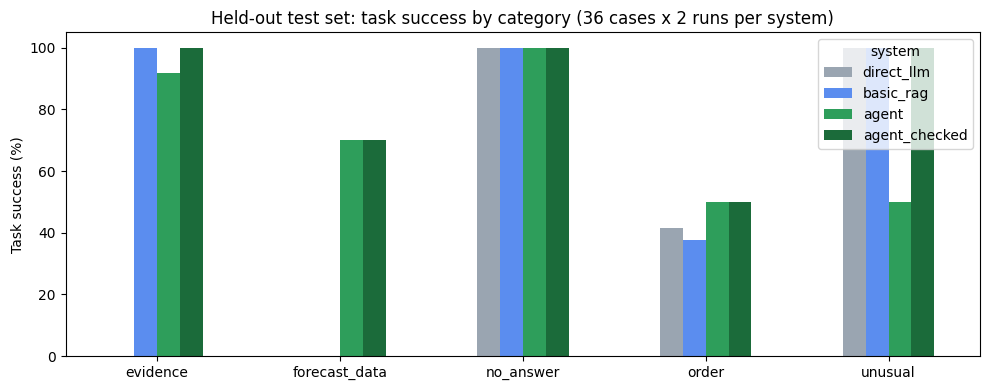

Same outcome in every run: {'direct_llm': '100%', 'basic_rag': '97%', 'agent': '97%', 'agent_checked': '100%'}
agent right and basic_rag wrong: 12 cases | basic_rag right and agent wrong: 5 cases
agent right and direct_llm wrong: 18 cases | direct_llm right and agent wrong: 5 cases
agent_checked right and agent wrong: 1 cases | agent right and agent_checked wrong: 0 cases


,covered,avg_leftover_units,runs
system,,,
direct_llm,50%,2.1,24
basic_rag,46%,-0.8,24
agent,100%,17.0,24
agent_checked,100%,17.0,24


In [14]:
runs = pd.read_csv(RUNS_FILE).drop_duplicates(["case_id", "system", "run"], keep="last")   # latest attempt of each run
runs = runs[runs["case_id"].isin(TEST["case_id"])]
if runs["error"].notna().any() or len(runs) < len(TEST) * len(SYSTEMS) * N_RUNS:
    print(f"Note: {int(runs['error'].notna().sum())} failed and {len(TEST) * len(SYSTEMS) * N_RUNS - len(runs)} missing runs. "
          "Finish section 5 before using these numbers.")
def frac(s):
    s = s.dropna().astype(bool)
    return f"{int(s.sum())} / {len(s)} ({100 * s.mean():.1f}%)" if len(s) else "-"
res = []
for s in SYSTEMS:
    d = runs[runs["system"] == s]
    res.append({"system": s, "task success": frac(d["success"]), "failed runs (errors)": int(d["error"].notna().sum()),
                "citations valid": frac(d["citations_valid"]), "numbers verified": frac(d["numbers_verified"]),
                "avg seconds / case": round(d["seconds"].mean(), 1), "model calls / case": round(d["model_calls"].mean(), 2),
                "tokens / case": int((d["prompt_tokens"] + d["completion_tokens"]).mean()) if len(d) else 0,
                "cost (USD, total)": round(d["cost_usd"].sum(), 4) if d["cost_usd"].notna().any() else "not reported"})
results_table = pd.DataFrame(res).set_index("system")
display(results_table)

by_cat = runs.pivot_table(index="category", columns="system", values="success", aggfunc=lambda x: f"{int(x.sum())}/{len(x)}").reindex(columns=SYSTEMS)
display(by_cat)
rate = runs.pivot_table(index="category", columns="system", values="success", aggfunc="mean").reindex(columns=SYSTEMS)
ax = (100 * rate).plot.bar(figsize=(10, 4), rot=0, color=["#9AA5B1", "#5B8DEF", "#2E9E5B", "#1B6B3A"][:len(SYSTEMS)])
ax.set_ylabel("Task success (%)"); ax.set_xlabel(""); ax.set_ylim(0, 105)
ax.set_title(f"Held-out test set: task success by category ({len(TEST)} cases x {N_RUNS} runs per system)")
plt.tight_layout(); plt.savefig(out_path("heldout_results.png"), dpi=200); plt.show()

# Run-to-run variation: share of cases whose outcome was the same in every run
stab = runs.groupby(["system", "case_id"])["success"].agg(lambda x: float(x.nunique() == 1) if len(x) > 1 else np.nan).groupby("system").mean()
print("Same outcome in every run:", {s: f"{100 * v:.0f}%" for s, v in stab.reindex(SYSTEMS).items() if pd.notna(v)})

# Where the systems disagree (majority outcome per case)
maj = runs.groupby(["case_id", "system"])["success"].mean().unstack().reindex(columns=SYSTEMS) >= 0.5
for a, b in [("agent", "basic_rag"), ("agent", "direct_llm"), ("agent_checked", "agent")]:
    if a in maj and b in maj:
        print(f"{a} right and {b} wrong: {int((maj[a] & ~maj[b]).sum())} cases | {b} right and {a} wrong: {int((~maj[a] & maj[b]).sum())} cases")
orders = runs[runs["category"] == "order"]
if len(orders):
    display(orders.groupby("system").agg(covered=("covered", lambda x: x.dropna().astype(float).mean()), avg_leftover_units=("leftover_units", "mean"), runs=("case_id", "size"))
            .reindex(SYSTEMS).style.format({"covered": "{:.0%}", "avg_leftover_units": "{:.1f}"}))

## 7. Error analysis
Every failed run gets one failure type (rules in section 4). Counts by system, then one example of each type with the answer, so the numbers can be checked against real outputs.

In [15]:
fails = runs[~runs["success"].astype(bool)]
display(fails.pivot_table(index="failure_type", columns="system", values="case_id", aggfunc="count", fill_value=0).reindex(columns=SYSTEMS, fill_value=0))
case_text = TEST.set_index("case_id")["input"]
for ft, g in fails.groupby("failure_type"):
    ex = g.iloc[0]
    print(f"\n=== {ft}: {ex['case_id']} ({ex['system']}, run {ex['run']}) ===\nCase: {case_text.get(ex['case_id'], '')}\nScore note: {ex['reason']}")
    print(str(ex["answer"])[:700] if isinstance(ex["answer"], str) else "(no answer)")
fails[["case_id", "category", "system", "run", "failure_type", "reason"]].to_csv(out_path("heldout_errors.csv"), index=False)

system,direct_llm,basic_rag,agent,agent_checked
failure_type,,,,
claimed no evidence wrongly,32,20,1,0
error / no answer,0,0,2,0
order did not cover demand,12,13,0,0
order far too large,2,2,12,12
wrong routing,0,0,6,6



=== claimed no evidence wrongly: t-q01 (direct_llm, run 1) ===
Case: What item is forecast to have the highest demand next week across our stores?
Score note: needs one of ['FOODS_3_586']
Answer: No supporting evidence found. I have no store sales, inventory, or forecasting data, so I cannot identify which item is forecast to have the highest demand for the week after 2016-01-14. To answer, I would need the demand forecast output for that week (item-level, by store or aggregated), along with the forecast model's run date and any promotions or known events that week.

Why:
- I have no access to forecast files, POS history, or a demand planning system.
- A forecast is a model output for specific data, so it cannot be inferred from general knowledge of retail trends.

What the data cannot tell us:
- Which item leads demand for the week after 2016-01-14 across your stores.
- Whet

=== error / no answer: t-q24 (agent, run 1) ===
Case: Which store has the highest predicted demand over the n

## 8. Hand review of the automatic scores (guide step 6.2)
The first cell writes `heldout_review_sheet_v4.csv`: about 18 runs spread over the systems and categories, with the answer and the automatic score. **Open it (Google Sheets or Excel), fill `human_success` with 1 or 0 and any notes, and save it in `RAG FILES/` as `heldout_review_sheet_filled_v4.csv`.** The second cell then reports how often the automatic score agreed with the person, and lists the disagreements to look at.

In [16]:
REVIEW_N = 18
rng = np.random.default_rng(SEED)
groups = list(runs[runs["run"] == 1].groupby(["system", "category"]))
pick = []
while len(pick) < min(REVIEW_N, (runs["run"] == 1).sum()):
    for _, g in groups:
        g = g[~g.index.isin(pick)]
        if len(g) and len(pick) < REVIEW_N:
            pick.append(rng.choice(g.index))
sheet = runs.loc[pick, ["case_id", "system", "run", "category", "answer", "success", "reason"]].rename(columns={"success": "auto_success", "reason": "auto_reason"})
sheet.insert(1, "input", sheet["case_id"].map(case_text))
sheet["expected_outcome"] = sheet["case_id"].map(TEST.set_index("case_id")["expected_outcome"])
sheet["human_success"] = ""; sheet["human_notes"] = ""
sheet.to_csv(out_path("heldout_review_sheet.csv"), index=False)
print(f"Wrote {len(sheet)} runs to review:", os.path.basename(out_path("heldout_review_sheet.csv")))

Wrote 18 runs to review: heldout_review_sheet_v4.csv


In [17]:
filled = out_path("heldout_review_sheet_filled.csv")
if os.path.exists(filled):
    hv = pd.read_csv(filled)
    hv = hv[hv["human_success"].astype(str).str.strip().isin(["0", "1", "0.0", "1.0"])]
    hv["human"] = hv["human_success"].astype(float).astype(bool); hv["auto"] = hv["auto_success"].astype(bool)
    agree = (hv["human"] == hv["auto"]).mean()
    print(f"Automatic score agrees with the hand score on {int((hv['human'] == hv['auto']).sum())} of {len(hv)} runs ({100 * agree:.0f}%)")
    print("Automatic success but human fail (false positives):", int((hv["auto"] & ~hv["human"]).sum()),
          "| automatic fail but human success (false negatives):", int((~hv["auto"] & hv["human"]).sum()))
    display(hv.loc[hv["human"] != hv["auto"], ["case_id", "system", "category", "auto_reason", "human_notes"]])
else:
    print("No filled review sheet yet: fill heldout_review_sheet_v4.csv and save it as heldout_review_sheet_filled_v4.csv in RAG FILES.")

No filled review sheet yet: fill heldout_review_sheet_v4.csv and save it as heldout_review_sheet_filled_v4.csv in RAG FILES.


## 9. Save
| File | What it holds |
|---|---|
| `heldout_cases_v4.json` / `.csv` | The case file: every development and test case with its expected outcome, evidence, scoring rule, split, provenance and reviewer |
| `heldout_runs_v4.csv` | Every run: answer, prompt, evidence IDs, time, calls, tokens, cost, score and failure type |
| `heldout_summary_v4.csv`, `heldout_results_v4.png` | The results table and the chart by category |
| `heldout_errors_v4.csv` | Every failed run with its failure type |
| `heldout_review_sheet_v4.csv` | Runs for the hand review |
| `heldout_run_info_v4.json` | Model, prompt versions, retrieval settings, data versions and the date of the run |

In [18]:
results_table.reset_index().assign(cases=len(TEST), runs_per_case=N_RUNS).to_csv(out_path("heldout_summary.csv"), index=False)
h = lambda s: hashlib.md5(s.encode()).hexdigest()[:8]
info = {"run_date": f"{pd.Timestamp.now():%Y-%m-%d %H:%M}", "model": rc.OPENROUTER_MODEL, "systems": SYSTEMS, "runs_per_case": N_RUNS,
        "test_cases": len(TEST), "development_cases": int((cases["split"] == "development").sum()), "case_reviewer": REVIEWER or "not reviewed yet",
        "prompt_versions": {"agent_order": h(rc.SYSTEM_PROMPT), "agent_question": h(rc.ASK_PROMPT), "direct_question": h(DIRECT_PROMPT),
                            "baseline_order": h(ORDER_PROMPT)},
        "retrieval": {"agent": "full (filters + hybrid + reranker)", "basic_rag": "dense (meaning only)", "relevance_min": rc.RELEVANCE_MIN,
                      "embed_model": rc.EMBED_MODEL, "rerank_model": rc.RERANK_MODEL},
        "data": {"library": LIBRARY_VERSION, "forecasts": CUBE_VERSION, "settings": rc.load_settings()},
        "rag_common_md5": hashlib.md5(open(rc.__file__, "rb").read()).hexdigest()[:8],
        "notes": "agent_checked's handling of missing dates/stores was added after the first partial run (case t-q24). Test cases are on 2016 dates and were not used for tuning. Question wording is synthetic and needs team review. "
                 "Evidence labels are automatic (expected document type + terms). Orders are scored on actual M5 sales the systems never see."}
with open(out_path("heldout_run_info.json"), "w") as f:
    json.dump(info, f, indent=1, default=str)
print("Saved to", RAG_DIR + ":", ", ".join(os.path.basename(out_path(n)) for n in
      ["heldout_cases.json", "heldout_cases.csv", "heldout_runs.csv", "heldout_summary.csv", "heldout_results.png", "heldout_errors.csv",
       "heldout_review_sheet.csv", "heldout_run_info.json"]))

Saved to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/: heldout_cases_v4.json, heldout_cases_v4.csv, heldout_runs_v4.csv, heldout_summary_v4.csv, heldout_results_v4.png, heldout_errors_v4.csv, heldout_review_sheet_v4.csv, heldout_run_info_v4.json
